In [1]:
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    mean_absolute_error,
    roc_auc_score,
    r2_score,
)
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.svm import SVC, SVR
from sklearn.compose import ColumnTransformer
from scipy.stats import ks_2samp
from sklearn.metrics import pairwise_distances

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 300
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 16
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16
plt.rcParams['legend.fontsize'] = 16
sns.set_palette('muted')

In [18]:
DATA_URL = (
    "https://raw.githubusercontent.com/julianmak/OCES4303_ML_ocean/"
    "refs/heads/main/PIDweekly_env_data.txt"
)
bacteria = pd.read_csv(DATA_URL, sep=r"\s+")

# Predicting weekly bacterial abundance across years

Marine bacterial communities follow seasonal cycles(Ward et al., 2017), but fixed season labels may miss transitional boundaries. This notebook asks:

> **How accurately can weekly bacterial abundance be predicted across years and, after applying a training-derived cutoff, classified as Low or High? Do continuous periodic time features and environmental measurements improve performance relative to a four-season baseline?**

The dataset contains 151 approximately weekly samples from three years. 

Models use the same training-derived Low/High definition and label every evaluation sample.

In [4]:
season_order = ["spring", "summer", "autumn", "winter"]
bacteria["Year"] = ((bacteria["YearDay"] - 1) // 365) + 1
bacteria["DayOfYear"] = ((bacteria["YearDay"] - 1) % 365) + 1
bacteria["LogAbundance"] = np.log10(bacteria["Bacteria_abundance"])
bacteria["NH4_uM"] = bacteria["NH4"] / 1000 # make it uM from nM according https://www.bco-dmo.org/dataset/956182 
# Dissolved Inorganic Nitrogen (DIN)# chemical notes: DIN = NH4 + NO2 + NO3
bacteria["DIN"] = bacteria["NH4_uM"] + bacteria["NO2.NO3"]
# winter = DecJanFeb, spring = MarAprMay, summer = JunJulAug, autumn = SepOctNov from the data_scrap.ipynb
season_conditions = [
    bacteria["DayOfYear"].between(60, 151),
    bacteria["DayOfYear"].between(152, 243),
    bacteria["DayOfYear"].between(244, 334),
]
bacteria["Season"] = pd.Categorical(
    np.select(season_conditions, season_order[:3], default="winter"),
    categories=season_order,
    ordered=True,
)
# finer harmonic features for day of year
for harmonic in range(1, 17):
    angle = 2 * np.pi * harmonic * (bacteria["DayOfYear"] - 1) / 365
    bacteria[f"Day_sin_{harmonic}"] = np.sin(angle)
    bacteria[f"Day_cos_{harmonic}"] = np.cos(angle)

for feature in ["Chlorophyll", "NH4_uM", "NO2.NO3", "PO4", "SiO4", "DIN", "DIC"]:
    bacteria[f"Log1p_{feature}"] = np.log1p(bacteria[feature].clip(lower=0))

Summary of Preprocessing tricks:
Dataset: PICO biogeochemical data collected from Duke Marine Lab dock from 2011-2022. They are not valided data according to the website and I find the unit is of NH4 is in nM, so I convert it to uM by dividing 1000. 
The dataset description and parameter can be found at https://www.bco-dmo.org/dataset/956182 

## 1. EDA: evidence for the model design

The EDA focuses on four decisions: transform the target, represent annual timing continuously, and expect some year-to-year transfer difficulty and environmental features selection.

### 1.1 Transformation the target

In [5]:
# low and high cutoff for the target variable, based on the mean of the training data
main_training_mask = bacteria["Year"].isin([1, 3])
main_testing_mask = bacteria["Year"].eq(2)
main_cutoff = bacteria.loc[main_training_mask, "LogAbundance"].mean()
bacteria["MainTarget"] = (bacteria["LogAbundance"] > main_cutoff).astype(int)
quality_summary = pd.DataFrame({
    "Rows": [len(bacteria)],
    "Duplicate SampleID": [bacteria["SampleID"].duplicated().sum()],
    "Missing predictor values": [bacteria.drop(
        columns=["SampleID", "Bacteria_abundance"]
    ).isna().sum().sum()],
    "Years": [bacteria["Year"].nunique()],
})

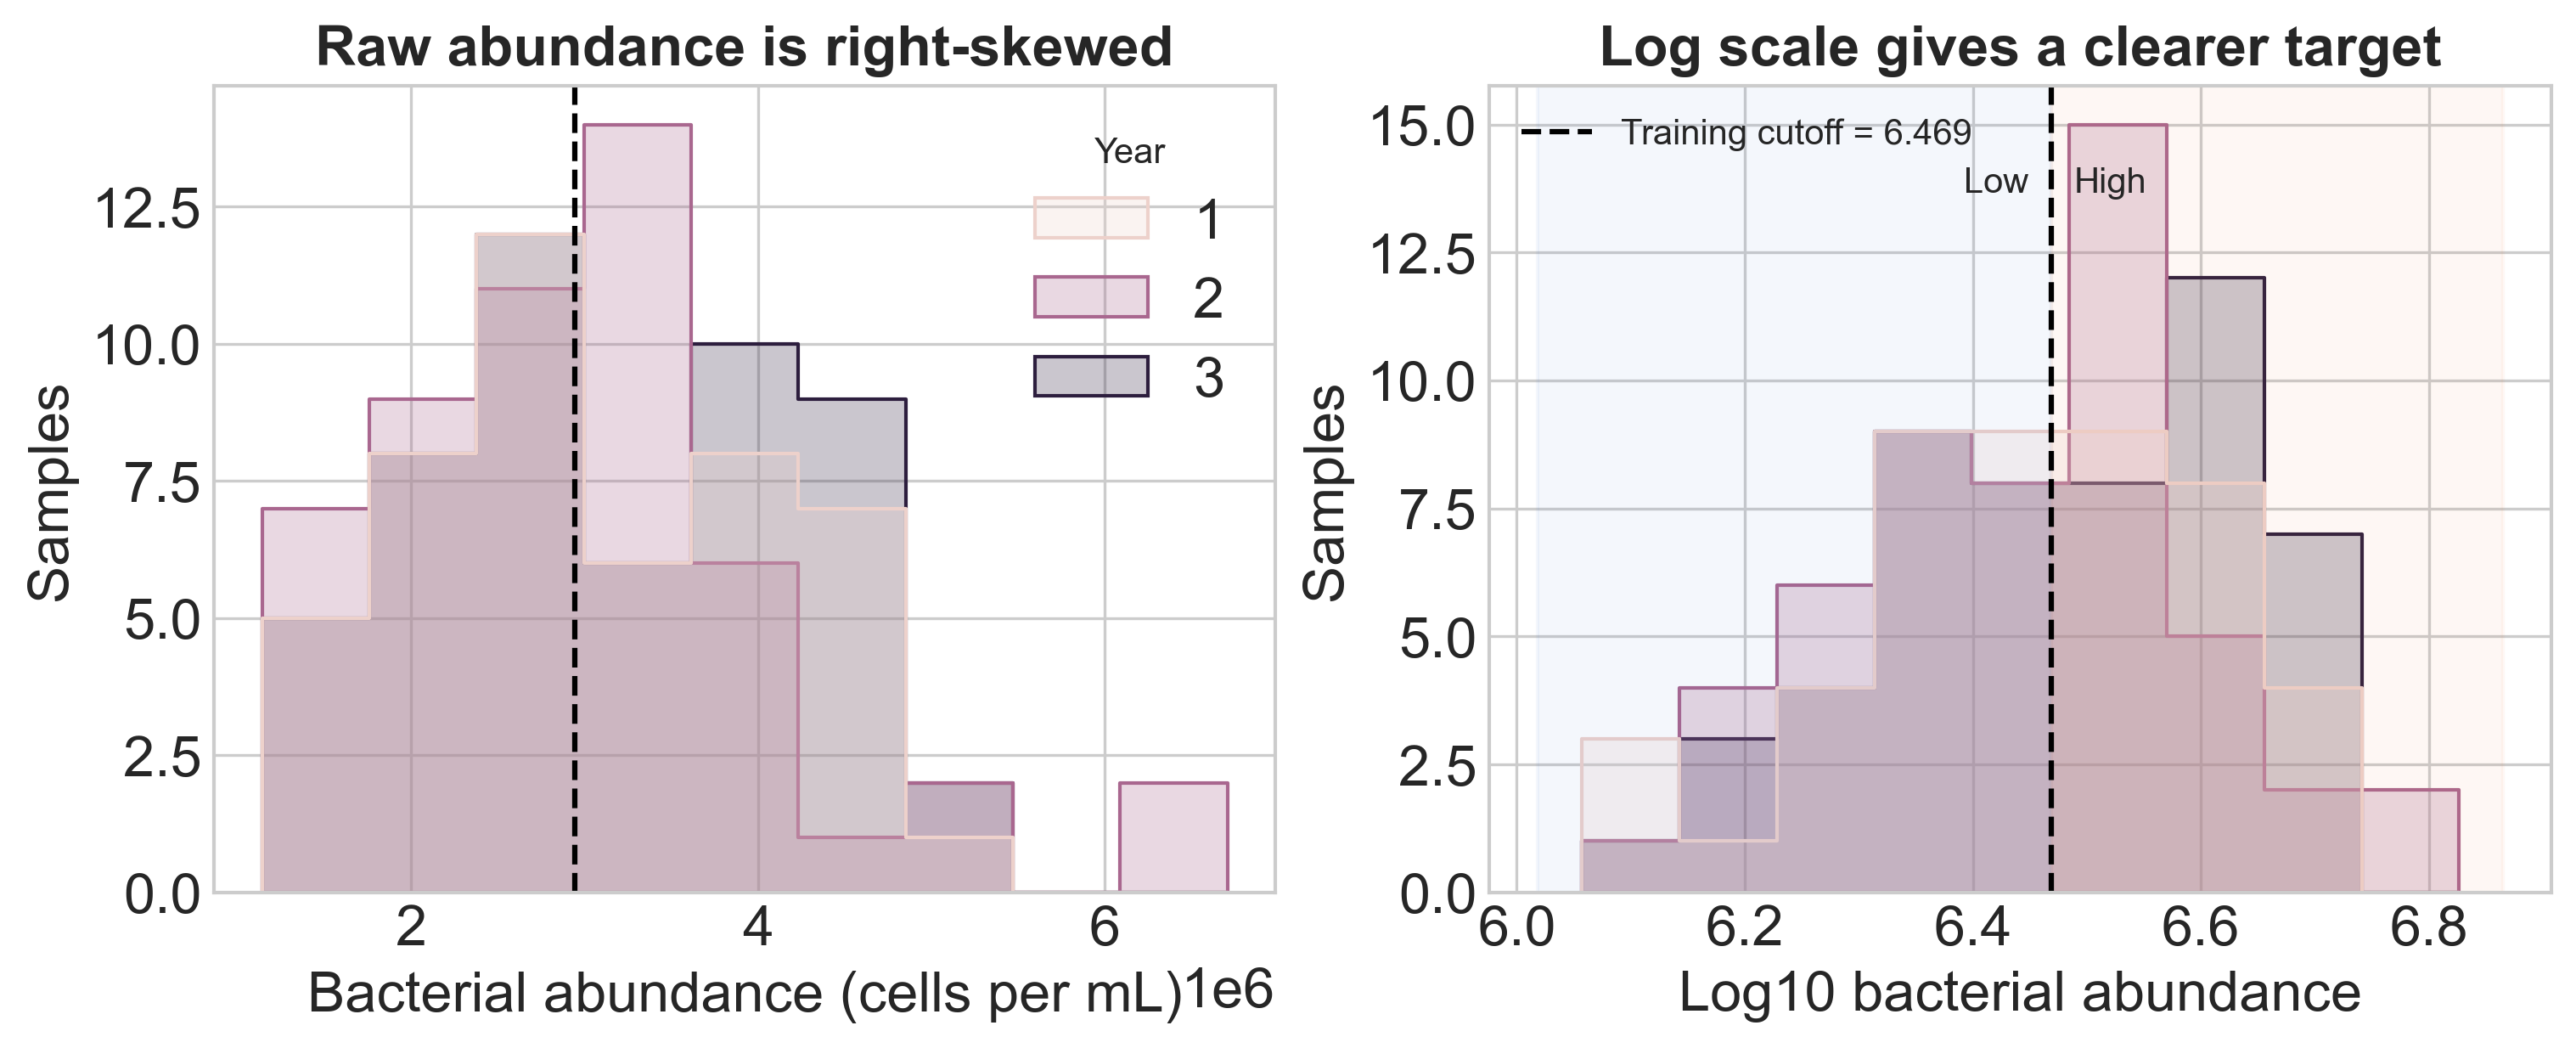

,Role,Years,N,Low,High
0,Training,1 and 3,99,46,53
1,Held-out Year 2,2,52,26,26


Equivalent raw cutoff: 2,944,772 cells mL⁻¹


In [6]:
figure, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
sns.histplot(
    data=bacteria, x="Bacteria_abundance", hue="Year",
    element="step", bins=9, common_norm=False, alpha=0.25, ax=axes[0],
)
axes[0].axvline(10 ** main_cutoff, color="black", linestyle="--", label="Cutoff")
axes[0].set(
    title="Raw abundance is right-skewed",
    xlabel="Bacterial abundance (cells per mL)",
    ylabel="Samples",
)
axes[0].ticklabel_format(style="sci", axis="x", scilimits=(6, 6))

sns.histplot(
    data=bacteria, x="LogAbundance", hue="Year",
    element="step", bins=9, common_norm=False, alpha=0.25, ax=axes[1],
)
left_limit, right_limit = axes[1].get_xlim()
axes[1].axvspan(left_limit, main_cutoff, color=sns.color_palette()[0], alpha=0.06)
axes[1].axvspan(main_cutoff, right_limit, color=sns.color_palette()[1], alpha=0.06)
axes[1].axvline(
    main_cutoff, color="black", linestyle="--",
    label=f"Training cutoff = {main_cutoff:.3f}",
)
axes[1].text(main_cutoff - 0.02, axes[1].get_ylim()[1] * 0.90, "Low",
             ha="right", va="top")
axes[1].text(main_cutoff + 0.02, axes[1].get_ylim()[1] * 0.90, "High",
             ha="left", va="top")
axes[1].set(
    title="Log scale gives a clearer target",
    xlabel="Log10 bacterial abundance",
    ylabel="Samples",
)
axes[1].legend(fontsize=10)
plt.show()

class_summary = pd.DataFrame({
    "Role": ["Training", "Held-out Year 2"],
    "Years": ["1 and 3", "2"],
    "N": [main_training_mask.sum(), main_testing_mask.sum()],
    "Low": [
        bacteria.loc[main_training_mask, "MainTarget"].eq(0).sum(),
        bacteria.loc[main_testing_mask, "MainTarget"].eq(0).sum(),
    ],
    "High": [
        bacteria.loc[main_training_mask, "MainTarget"].eq(1).sum(),
        bacteria.loc[main_testing_mask, "MainTarget"].eq(1).sum(),
    ],
})
display(class_summary)
print(f"Equivalent raw cutoff: {10 ** main_cutoff:,.0f} cells mL⁻¹")

**Implication.** Target are set on log10 abundance so very large counts do not dominate the fit. Thus, log-transform chosen to be one of the pre-processing steps. The dashed line is the only cutoff used by every model in the main experiment: High is strictly above it; Low is at or below it. 

In [7]:
correlation_columns = [
    "Bacteria_abundance", "LogAbundance", "DayOfYear",
    "Projected_Daily_Insolation", "Temp", "MLLW", "Salinity",
    "Oxygen_Saturation", "pH", "DIC", "Chlorophyll",
    "NH4_uM", "NO2.NO3", "PO4", "SiO4","DIN"
]
correlation_matrix = bacteria[correlation_columns].corr(method="pearson")

target_correlations = (
    correlation_matrix["LogAbundance"]
    .drop(["LogAbundance", "Bacteria_abundance"])
    .sort_values(key=np.abs, ascending=False)
    .rename("Correlation with log10 abundance")
    .to_frame()
)
display(target_correlations.round(3))

,Correlation with log10 abundance
Projected_Daily_Insolation,0.497
Temp,0.460
Chlorophyll,0.395
SiO4,0.308
MLLW,-0.260
DayOfYear,0.115
DIC,-0.102
pH,0.068
Salinity,-0.044
NH4_uM,-0.037


**Implication.** Time, physical conditions and chemistry overlap strongly, so unregularized coefficients would be unstable.

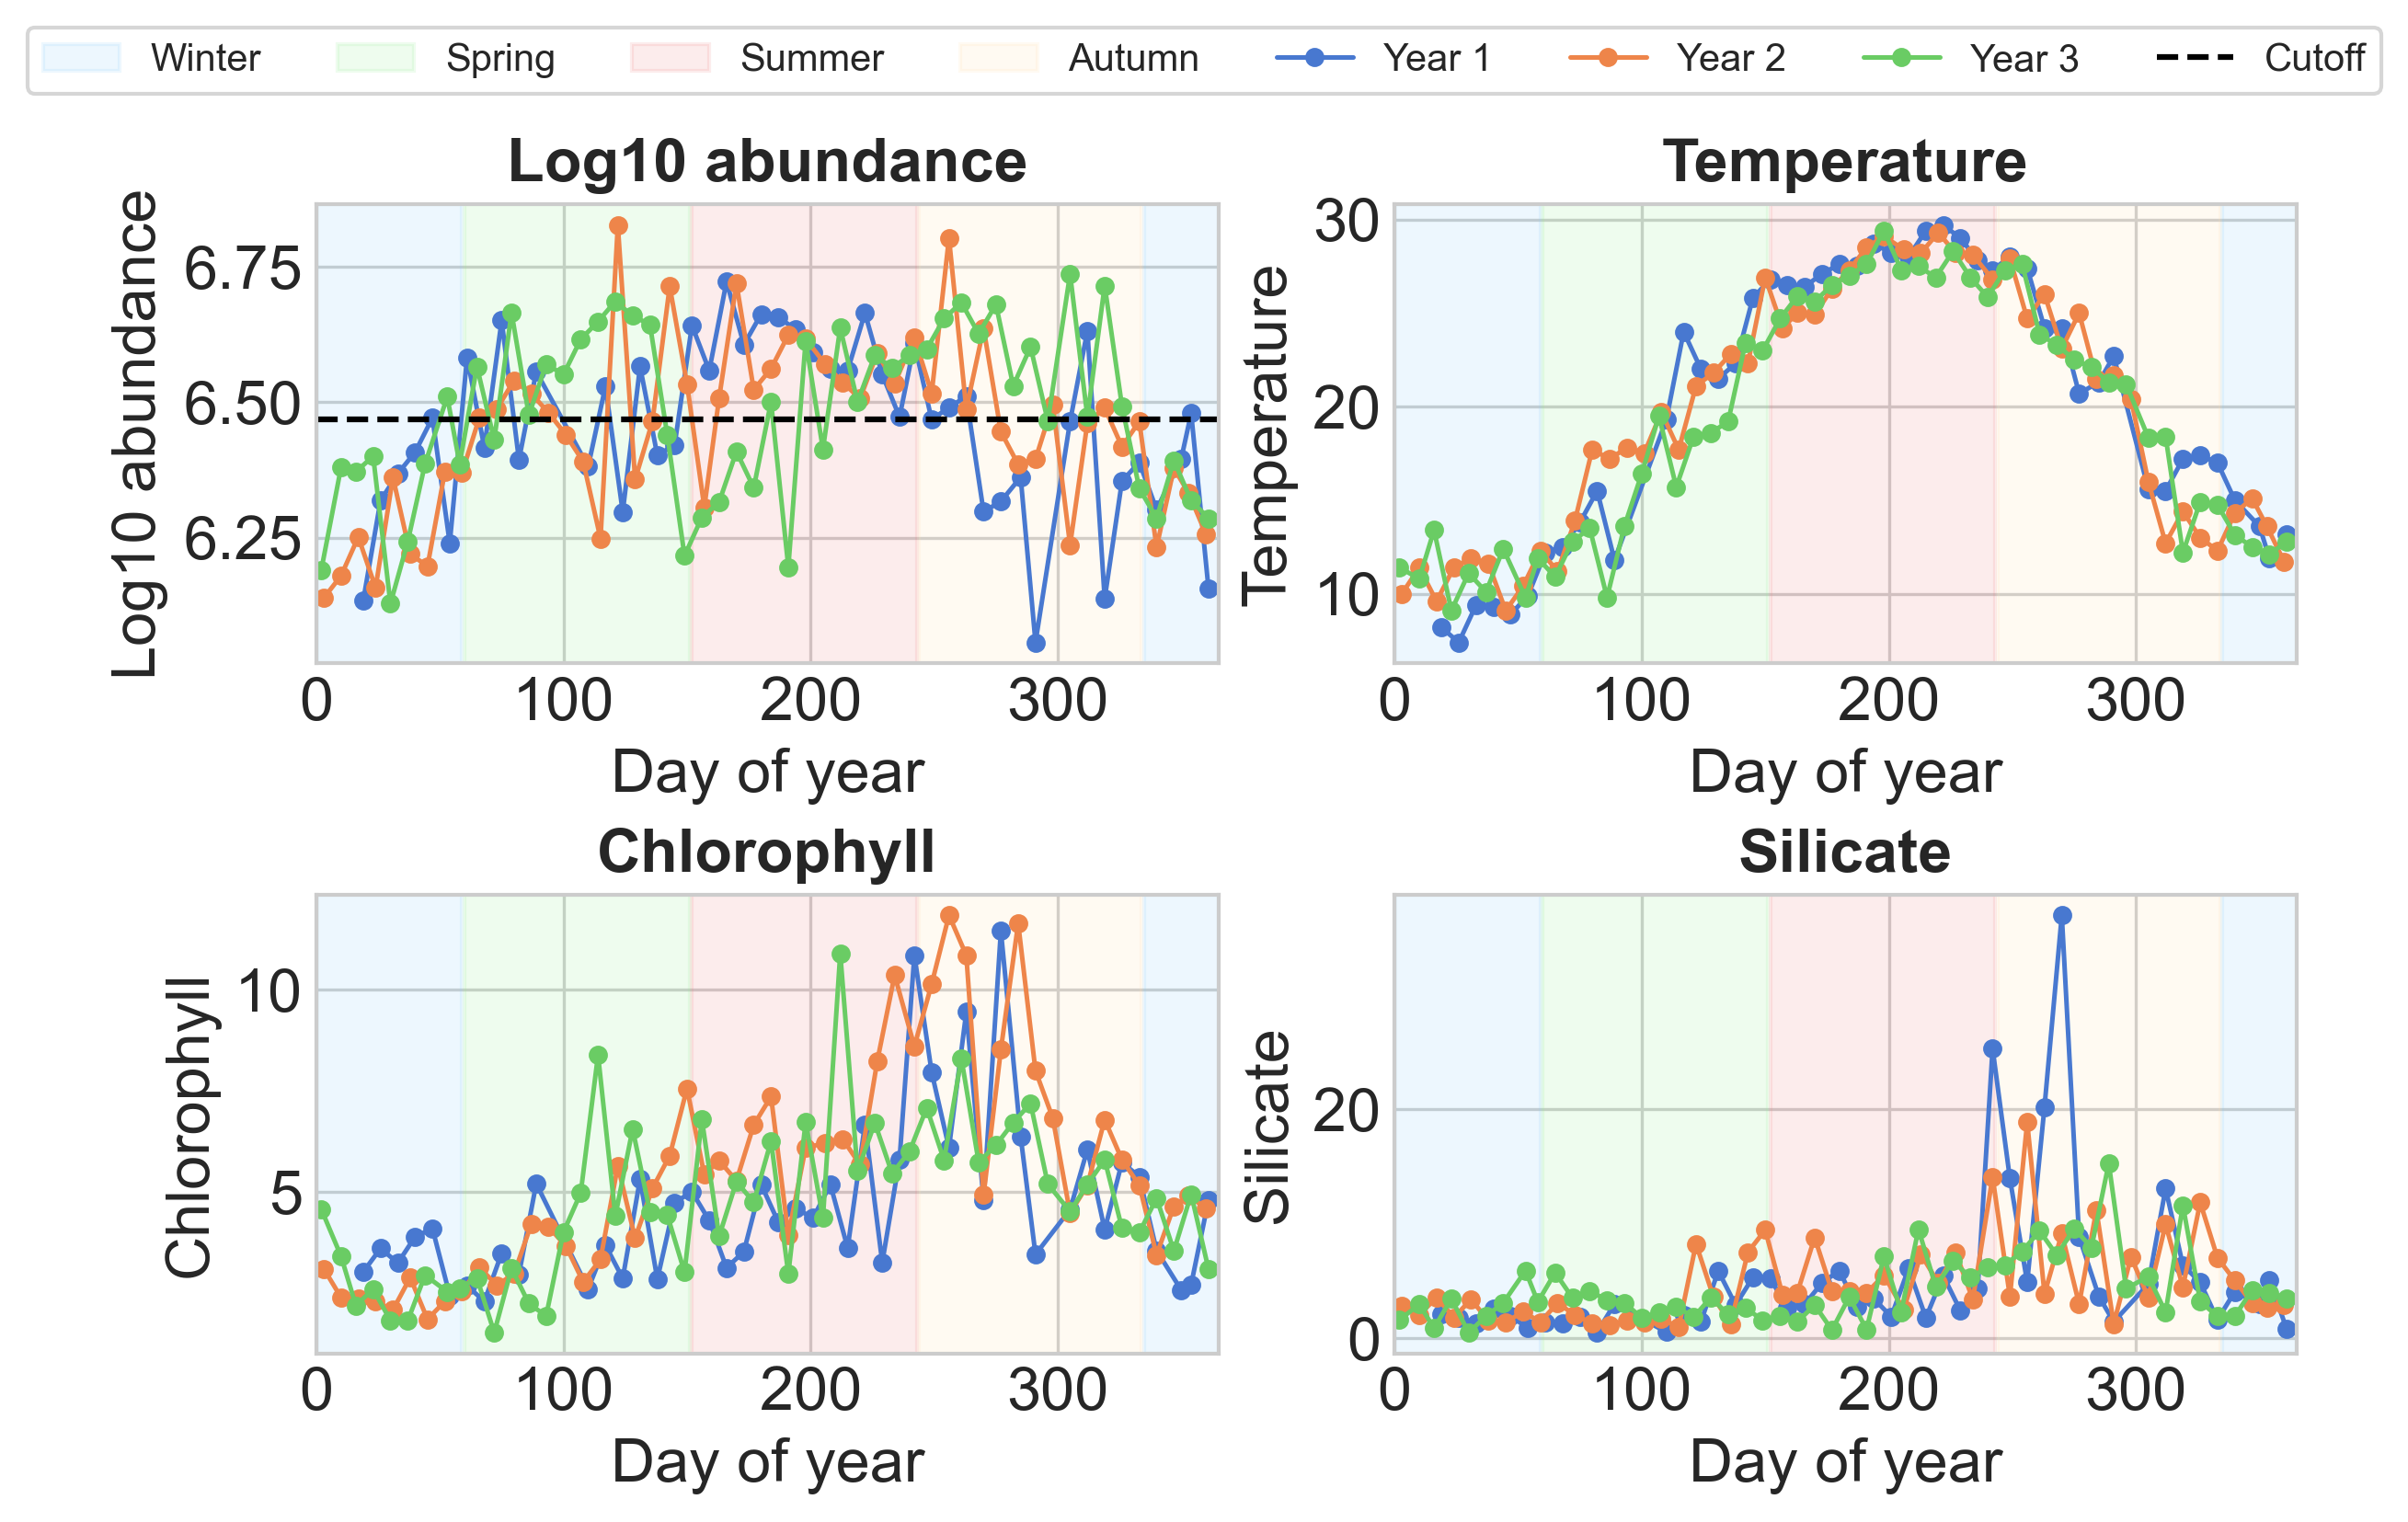

In [8]:
# add season as background of the plots
seasons = [
    {"name": "Winter", "range": (0, 59), "color": "lightskyblue"},
    {"name": "Spring", "range": (60, 151), "color": "lightgreen"},
    {"name": "Summer", "range": (152, 243), "color": "lightcoral"},
    {"name": "Autumn", "range": (244, 334), "color": "navajowhite"},
    {"name": "Winter (End)", "range": (335, 365), "color": "lightskyblue"}
]

cycle_variables = {
    "LogAbundance": "Log10 abundance",
    "Temp": "Temperature",
    "Chlorophyll": "Chlorophyll",
    "SiO4": "Silicate",
}

figure, axes = plt.subplots(2, 2, figsize=(8, 5), constrained_layout=True)

for axis, (variable, label) in zip(axes.flat, cycle_variables.items()):
    for season in seasons:
        legend_label = season["name"] if variable == "LogAbundance" and "End" not in season["name"] else ""
        axis.axvspan(season["range"][0], season["range"][1], color=season["color"], alpha=0.15, label=legend_label)
    for year, yearly_data in bacteria.groupby("Year"):
        yearly_data = yearly_data.sort_values("DayOfYear")
        axis.plot(
            yearly_data["DayOfYear"], yearly_data[variable],
            marker="o", markersize=4, linewidth=1.2, label=f"Year {year}" if variable == "LogAbundance" else "",
        )
        
    if variable == "LogAbundance":
        axis.axhline(main_cutoff, color="black", linestyle="--", label="Cutoff")
        
    axis.set(title=label, xlabel="Day of year", ylabel=label)
    axis.set_xlim(0, 365)

handles, labels = axes[0, 0].get_legend_handles_labels()
by_label = dict(zip(labels, handles))
figure.legend(
    by_label.values(), 
    by_label.keys(), 
    loc="lower center", 
    bbox_to_anchor=(0.5, 1.01), 
    ncol=8, 
    fontsize=10, 
    frameon=True
)

plt.show()

**Implication.** The broad cycle of abundance, chlorophyll and temperature repeats, but its amplitude and transition timing change between years. Four season labels capture the broad pattern

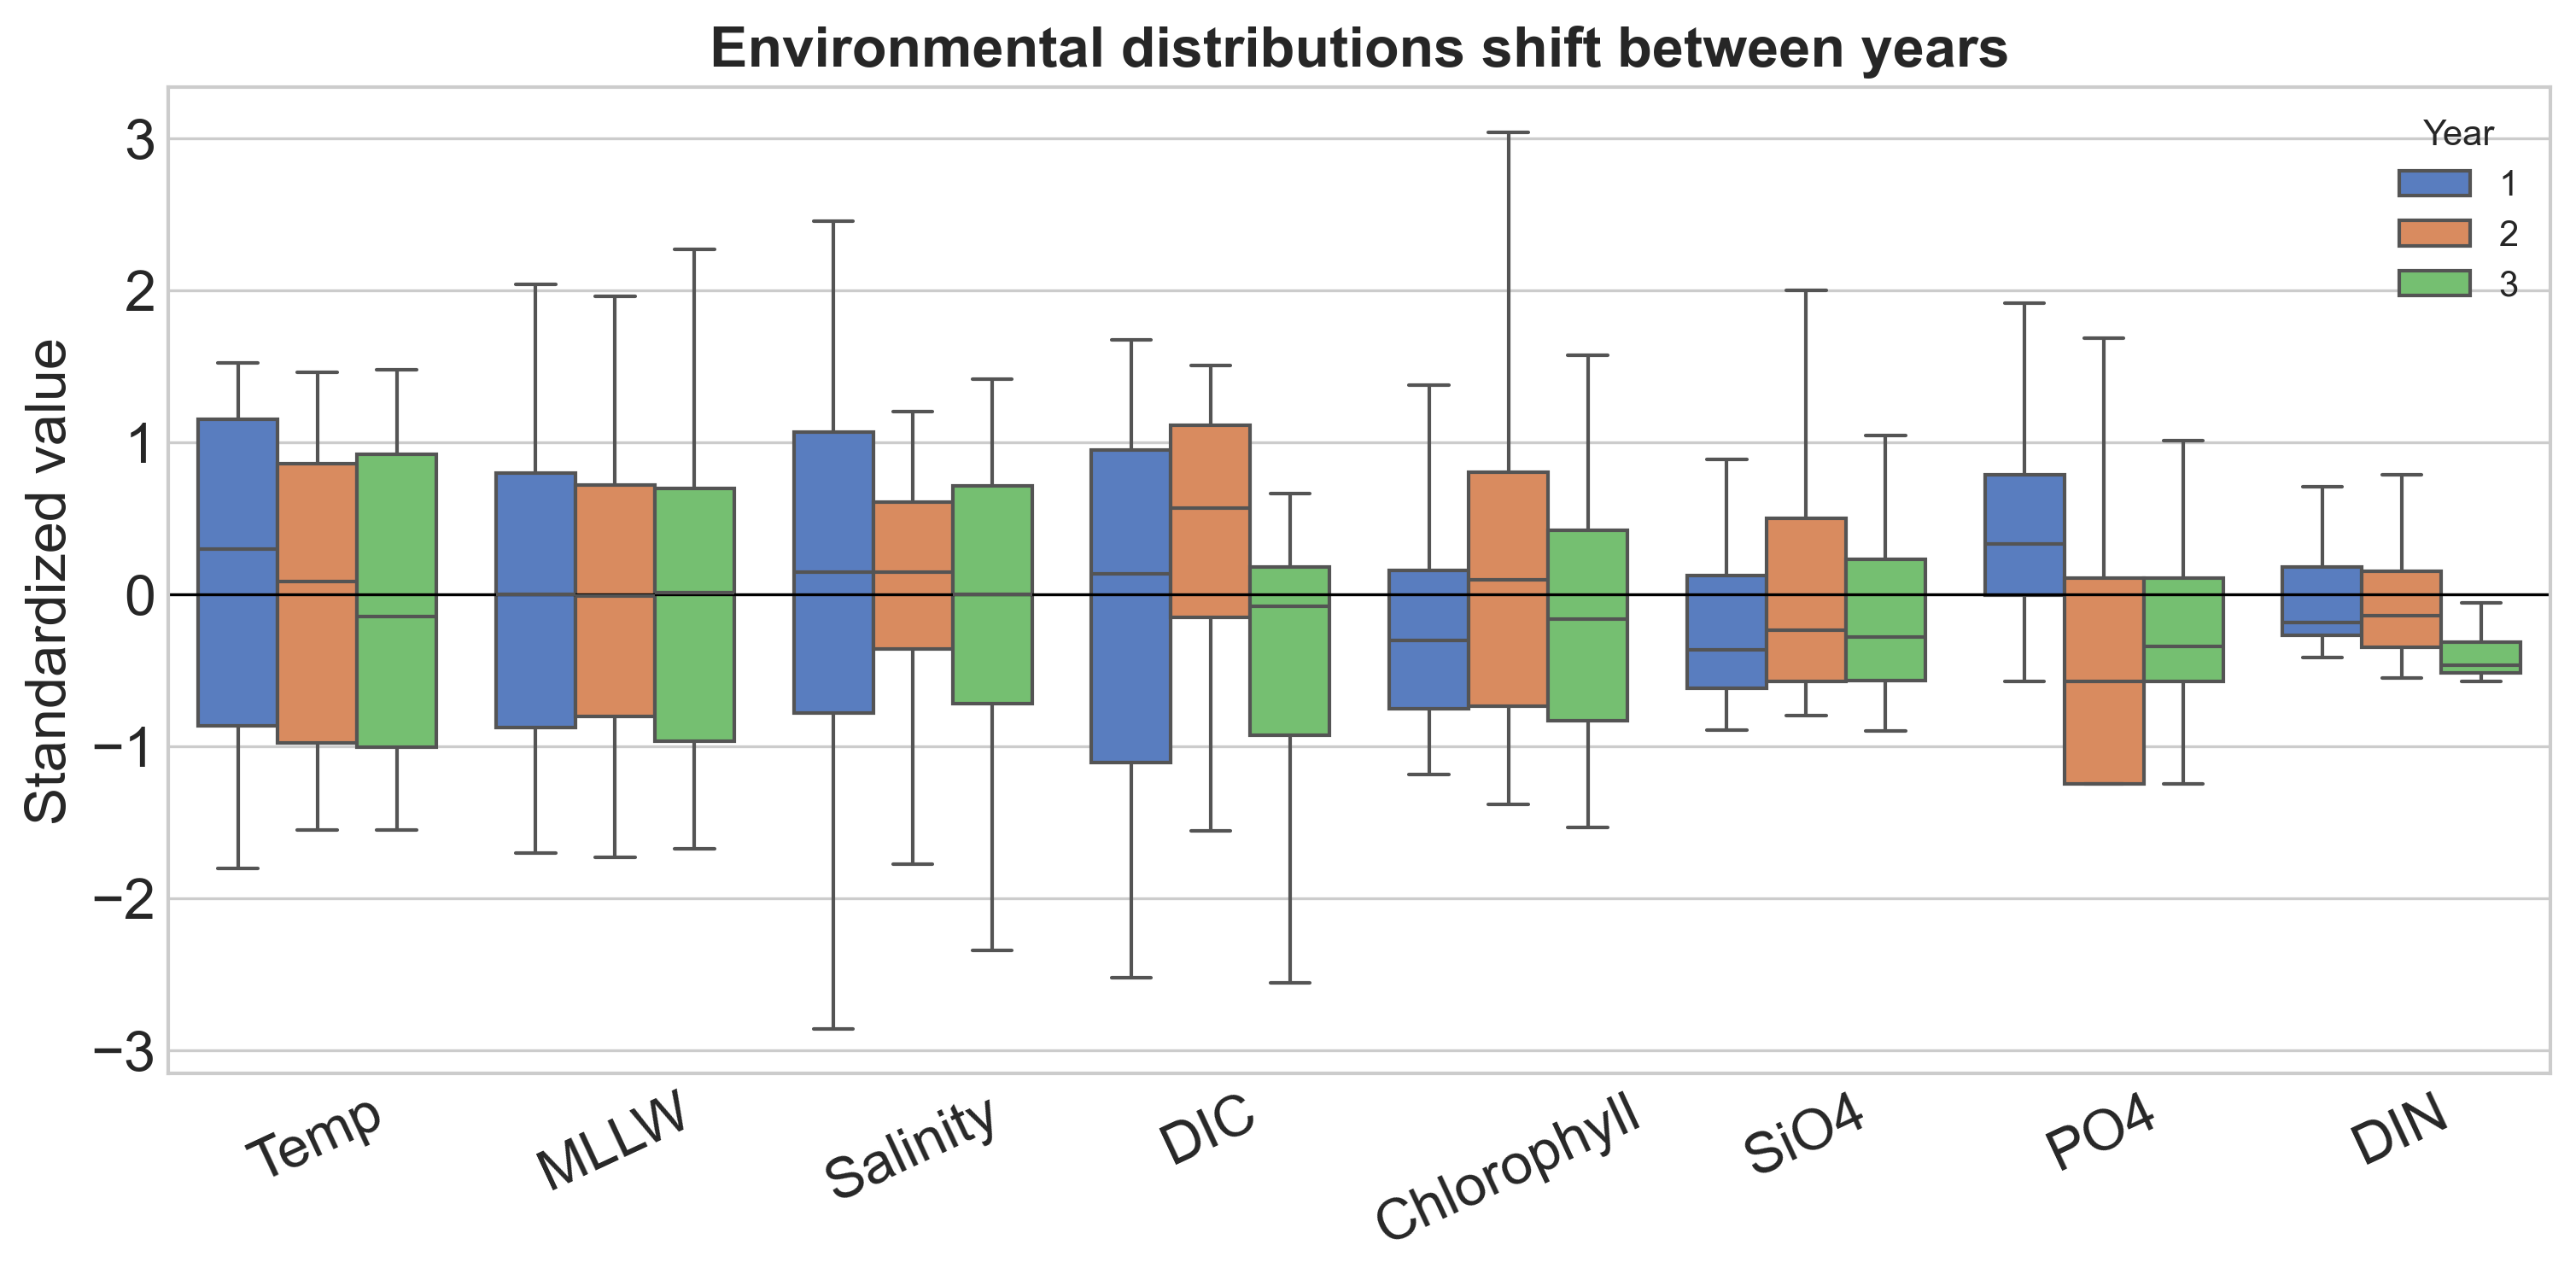

In [9]:
shift_features = [
    "Temp", "MLLW", "Salinity",
    "DIC", "Chlorophyll", "SiO4","PO4","DIN"
]
standardized_shift = bacteria[shift_features].apply(
    lambda column: (column - column.mean()) / column.std()
)
shift_plot_data = (
    standardized_shift.assign(Year=bacteria["Year"].astype(str))
    .melt(id_vars="Year", var_name="Feature", value_name="Standardized value")
)

figure, axis = plt.subplots(figsize=(12, 5))
sns.boxplot(
    data=shift_plot_data, x="Feature", y="Standardized value",
    hue="Year", showfliers=False, ax=axis,
)
axis.axhline(0, color="black", linewidth=0.8)
axis.set(title="Environmental distributions shift between years", xlabel="", ylabel="Standardized value")
axis.tick_params(axis="x", rotation=25)
axis.legend(title="Year", fontsize=10)
plt.show()

**Implication.**  The above final environmental features are selected due to their "similar distrubution" arcoss 3 years and their chemial and physical uniqueness. Others like Projected_Daily_Insolation, No2.No3 and NH4 are believed to be represented in the above features already. (Of course, the above combinations of the choices are also selected by hindsight from downstream prediction performance which the notebook do not explictly show. For example, pH and Oxygen_Saturation hinder the performance)

In [10]:
features = [ 'Bacteria_abundance',
       'Projected_Daily_Insolation', 'Temp', 'MLLW', 'Salinity',
       'Oxygen_Saturation', 'pH', 'DIC', 'Chlorophyll', 'NH4', 'NO2.NO3',]

distribution_shift_columns = [
    "DayOfYear",
    *features,
    "LogAbundance",  
]

sampling_years = sorted(bacteria["Year"].unique())
sampling_year_pairs = [
    (first_year, second_year)
    for year_index, first_year in enumerate(sampling_years)
    for second_year in sampling_years[year_index + 1:]
]

# 3. Calculate Kolmogorov-Smirnov statistics
distribution_shift_rows = []
for variable in distribution_shift_columns:
    for first_year, second_year in sampling_year_pairs:
        first_values = bacteria.loc[bacteria["Year"].eq(first_year), variable].dropna()
        second_values = bacteria.loc[bacteria["Year"].eq(second_year), variable].dropna()
        
        ks_result = ks_2samp(first_values, second_values, method="asymp")
        
        distribution_shift_rows.append({
            "variable": variable,
            "year_pair": f"Year {first_year} vs {second_year}",
            "ks_statistic": ks_result.statistic,
        })

distribution_shift_results = pd.DataFrame(distribution_shift_rows)
distribution_shift_matrix = distribution_shift_results.pivot(
    index="variable", columns="year_pair", values="ks_statistic"
)


maximum_shift_indices = distribution_shift_results.groupby("variable")["ks_statistic"].idxmax()
maximum_shift_summary = (
    distribution_shift_results.loc[maximum_shift_indices]
    .sort_values("ks_statistic", ascending=False)
    .reset_index(drop=True)
)

print("=== Maximum Distribution Shift per Variable ===")
display(maximum_shift_summary.round(3))

=== Maximum Distribution Shift per Variable ===


,variable,year_pair,ks_statistic
0,NH4,Year 1 vs 3,0.786
1,Oxygen_Saturation,Year 1 vs 3,0.633
2,DIC,Year 2 vs 3,0.481
3,NO2.NO3,Year 1 vs 2,0.414
4,pH,Year 1 vs 3,0.353
5,Salinity,Year 1 vs 3,0.283
6,Chlorophyll,Year 1 vs 2,0.230
7,Bacteria_abundance,Year 2 vs 3,0.212
8,LogAbundance,Year 2 vs 3,0.212
9,MLLW,Year 1 vs 3,0.144


**Implication.**  Rationale for Training on Year 1 and Year 3

Exploratory Data Analysis revealed severe inter-annual distribution shifts in critical biogeochemical markers. The Kolmogorov-Smirnov (KS) statistics (a reference probability distribution or whether two samples come from the same distribution) show the maximum divergence occurs between **Year 1 and Year 3** (e.g., `NH4` KS = 0.79, `Oxygen_Saturation` KS = 0.63). By deliberately selecting Years 1 and 3 as the primary training set, the models are exposed to the maximum possible variance and volatility in the ecosystem's chemical profile.

### 2. Experimental Setup & Selected Models
**Data Shape & Validation Geometry**
The binary cutoff is dynamically derived from the training set's mean log-abundance. 

**2.1 Phase 1: Time Representation Baselines (No Abiotic Features)**
Initial models evaluate pure temporal inputs to determine the optimal architecture:
* **Inputs:** Categorical (`Season`) vs. Continuous (2 Fourier harmonics).
* **Models:** SVC (Direct Classification) vs. SVR (Regression thresholded to class).
* **Conclusion:** Continuous harmonics outperform categorical seasons, establishing regression-to-classification as the optimal pipeline.


**2.2 Phase 2: Time + Environmental Models**
(To prevent temporal leakage during hyperparameter tuning, inner validation uses **Year-CV** (`GroupKFold` grouped by `Year`). All imputation and scaling are strictly encapsulated within pipelines)
The finalized pipelines integrate 8 abiotic features (`Temp`, `MLLW`, `Salinity`, and log-transformed nutrients) with higher-frequency temporal waves:

| Model | Temporal Features | Env. Features | Task & Suitability |
| :--- | :--- | :--- | :--- |
| **Ridge** | 8 Harmonics (16 vars) | 8 variables | L2-regularized linear regression. Excels at tracking smooth, additive seasonal inertia. |
| **SVR (RBF)** | 6 Harmonics (12 vars) | 8 variables | Non-linear regression. Captures complex abiotic interactions; temporal resolution is restricted to prevent calendar memorization. |


## 2.1 Phase 1: Time Representation Baselines (No Abiotic Features)

In [11]:
features_season = ["Season"]
features_continuous = ["Day_sin_1", "Day_cos_1", "Day_sin_2", "Day_cos_2"] # Annual + Semi-annual cycles
X_train = bacteria.loc[main_training_mask]
X_test = bacteria.loc[main_testing_mask]
y_train_class = bacteria.loc[main_training_mask, "MainTarget"]
y_test_class = bacteria.loc[main_testing_mask, "MainTarget"]
y_train_reg = bacteria.loc[main_training_mask, "LogAbundance"]
y_test_reg = bacteria.loc[main_testing_mask, "LogAbundance"]


# A. SVC (Classification) 
pipe_svc_season = Pipeline([
    ('prep', ColumnTransformer([('cat', OneHotEncoder(drop='first'), features_season)])),
    ('classifier', SVC(kernel='linear', random_state=42))
])

# B. SVC (Classification) - Continuous Time
pipe_svc_cont = Pipeline([
    ('prep', ColumnTransformer([('num', StandardScaler(), features_continuous)])),
    ('classifier', SVC(kernel='linear', random_state=42))
])

# C. SVR (Regression) - Categorical Season
pipe_svr_season = Pipeline([
    ('prep', ColumnTransformer([('cat', OneHotEncoder(drop='first'), features_season)])),
    ('regressor', SVR(kernel='rbf')) # RBF kernel is typically better for continuous SVR
])

# D. SVR (Regression) - Continuous Time
pipe_svr_cont = Pipeline([
    ('prep', ColumnTransformer([('num', StandardScaler(), features_continuous)])),
    ('regressor', SVR(kernel='rbf'))
])

pipe_svc_season.fit(X_train[features_season], y_train_class)
pipe_svc_cont.fit(X_train[features_continuous], y_train_class)
pipe_svr_season.fit(X_train[features_season], y_train_reg)
pipe_svr_cont.fit(X_train[features_continuous], y_train_reg)

acc_svc_season = accuracy_score(y_test_class, pipe_svc_season.predict(X_test[features_season]))
acc_svc_cont = accuracy_score(y_test_class, pipe_svc_cont.predict(X_test[features_continuous]))
pred_svr_season = pipe_svr_season.predict(X_test[features_season])
r2_svr_season = r2_score(y_test_reg, pred_svr_season)
acc_svr_season_thresh = accuracy_score(y_test_class, (pred_svr_season > main_cutoff).astype(int))
pred_svr_cont = pipe_svr_cont.predict(X_test[features_continuous])
r2_svr_cont = r2_score(y_test_reg, pred_svr_cont)
acc_svr_cont_thresh = accuracy_score(y_test_class, (pred_svr_cont > main_cutoff).astype(int))

# Combine Results into a Table
comparison_df = pd.DataFrame({
    "Model Task": ["Classification (SVC)", "Classification (SVC)", "Regression (SVR)", "Regression (SVR)"],
    "Time Representation": ["Categorical (Season)", "Continuous (Harmonics)", "Categorical (Season)", "Continuous (Harmonics)"],
    "Target": ["MainTarget", "MainTarget", "LogAbundance", "LogAbundance"],
    "Classification Accuracy": [acc_svc_season, acc_svc_cont, acc_svr_season_thresh, acc_svr_cont_thresh],
    "Regression R2 Score": ["N/A", "N/A", r2_svr_season, r2_svr_cont]
})

display(comparison_df)

,Model Task,Time Representation,Target,Classification Accuracy,Regression R2 Score
0,Classification (SVC),Categorical (Season),MainTarget,0.750000,N/A
1,Classification (SVC),Continuous (Harmonics),MainTarget,0.807692,N/A
2,Regression (SVR),Categorical (Season),LogAbundance,0.750000,0.454438
3,Regression (SVR),Continuous (Harmonics),LogAbundance,0.807692,0.466214


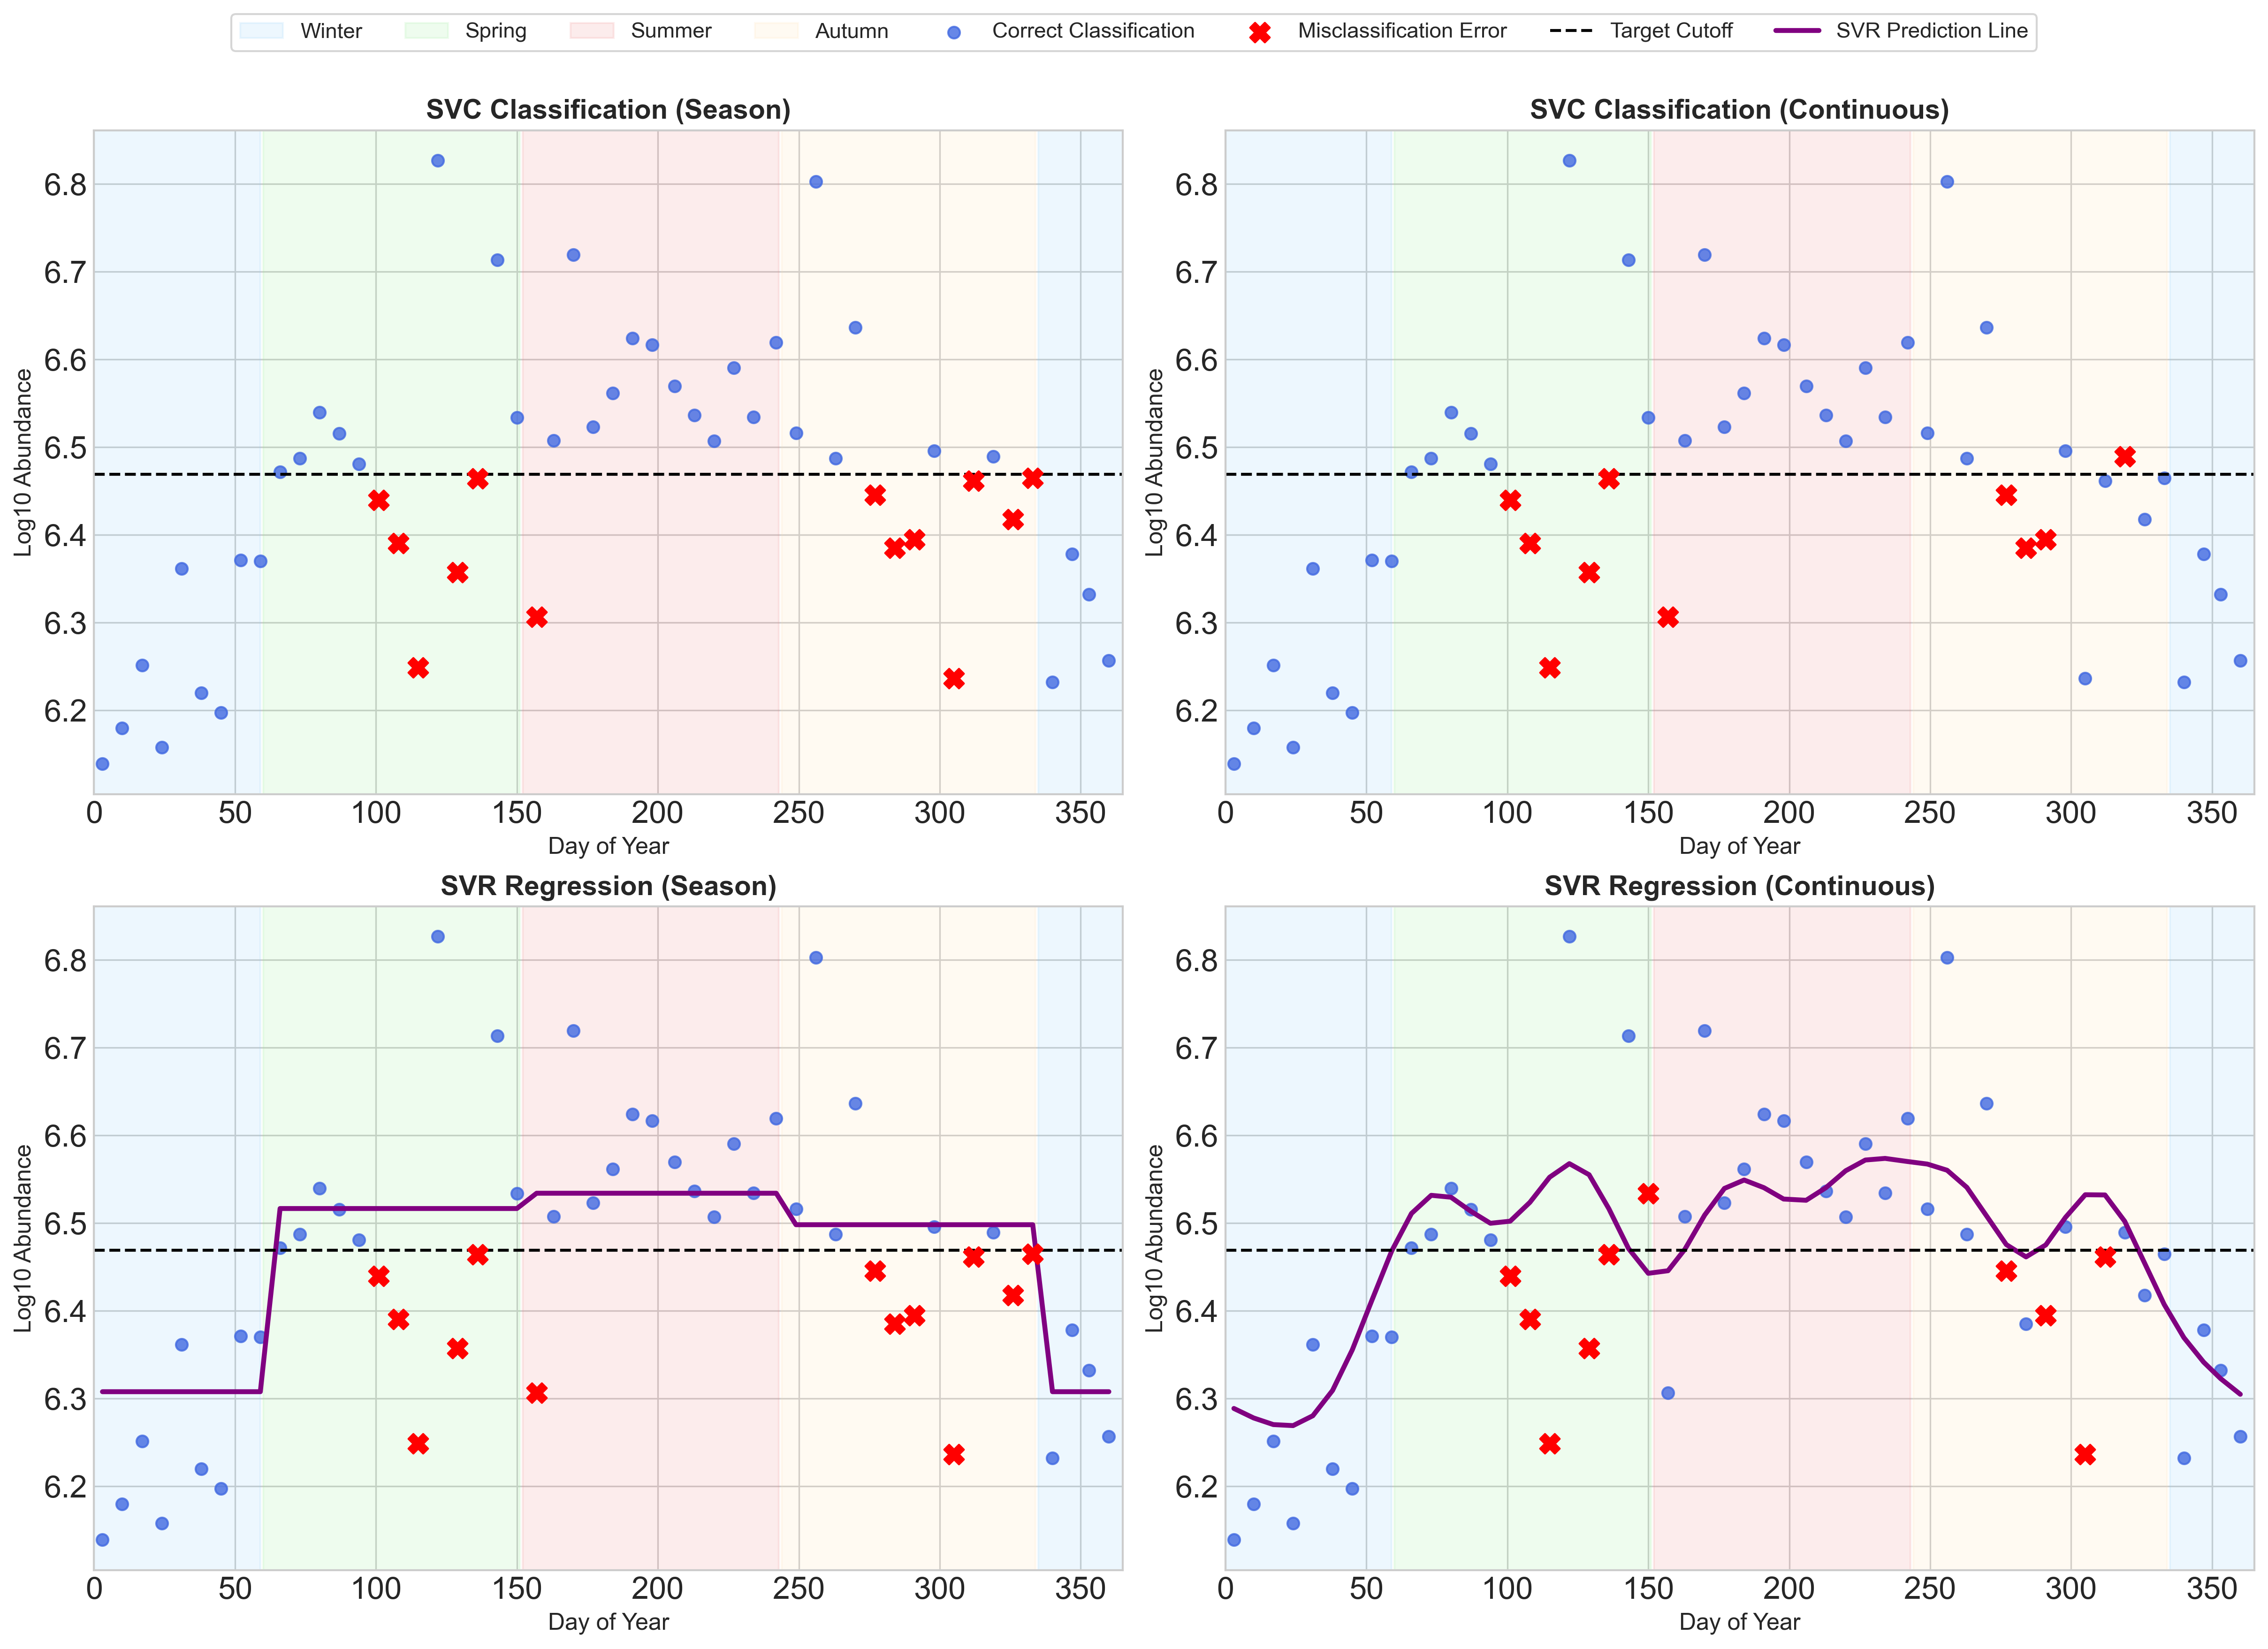

In [12]:
X_test = bacteria.loc[main_testing_mask].copy()
X_test["Pred_SVC_Season"] = pipe_svc_season.predict(X_test[features_season])
X_test["Pred_SVC_Cont"] = pipe_svc_cont.predict(X_test[features_continuous])
X_test["Pred_SVR_Season"] = pipe_svr_season.predict(X_test[features_season])
X_test["Pred_SVR_Cont"] = pipe_svr_cont.predict(X_test[features_continuous])

X_test["Err_SVC_Season"] = X_test["Pred_SVC_Season"] != X_test["MainTarget"]
X_test["Err_SVC_Cont"] = X_test["Pred_SVC_Cont"] != X_test["MainTarget"]
X_test["Err_SVR_Season"] = (X_test["Pred_SVR_Season"] > main_cutoff).astype(int) != X_test["MainTarget"]
X_test["Err_SVR_Cont"] = (X_test["Pred_SVR_Cont"] > main_cutoff).astype(int) != X_test["MainTarget"]
X_test = X_test.sort_values("DayOfYear")


models_to_plot = [
    ("SVC Classification (Season)", "Err_SVC_Season", None),
    ("SVC Classification (Continuous)", "Err_SVC_Cont", None),
    ("SVR Regression (Season)", "Err_SVR_Season", "Pred_SVR_Season"),
    ("SVR Regression (Continuous)", "Err_SVR_Cont", "Pred_SVR_Cont"),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 11), constrained_layout=True)

for ax, (title, err_col, pred_col) in zip(axes.flat, models_to_plot):
    # Overlay Background Seasons
    for season in seasons:
        legend_label = season["name"] if "End" not in season["name"] else ""
        ax.axvspan(season["range"][0], season["range"][1], color=season["color"], alpha=0.15, label=legend_label)
        
    correct = X_test[~X_test[err_col]]
    errors = X_test[X_test[err_col]]
    
    ax.scatter(correct["DayOfYear"], correct["LogAbundance"], color="royalblue", alpha=0.8, marker="o", label="Correct Classification")
    ax.scatter(errors["DayOfYear"], errors["LogAbundance"], color="red", s=100, marker="X", zorder=5, label="Misclassification Error")
    
    # Plot SVR prediction curve if it's a regression model
    if pred_col:
        ax.plot(X_test["DayOfYear"], X_test[pred_col], color="purple", linestyle="-", linewidth=2.5, label="SVR Prediction Line")
        
    # Main target cutoff line
    ax.axhline(main_cutoff, color="black", linestyle="--", label="Target Cutoff")
    
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xlabel("Day of Year", fontsize=12)
    ax.set_ylabel("Log10 Abundance", fontsize=12)
    ax.set_xlim(0, 365)

handles, labels = axes[0, 0].get_legend_handles_labels()
handles_svr, labels_svr = axes[1, 0].get_legend_handles_labels()
all_handles = handles + [h for h, l in zip(handles_svr, labels_svr) if l == "SVR Prediction Line"]
all_labels = labels + ["SVR Prediction Line"]

by_label = dict(zip(all_labels, all_handles))

fig.legend(
    by_label.values(), 
    by_label.keys(), 
    loc="lower center", 
    bbox_to_anchor=(0.5, 1.02), 
    ncol=8, 
    fontsize=11, 
    frameon=True
)

plt.show()

**Implication: Transitional Boundaries and the Shift to Continuous SVR**

The time-only ablation study reveals how much can be predicted from the calendar alone and finer temperal information can indeed improve model performance.

* **Time is Inherently Continuous:** When only train with time featues, the continuous harmonic representation of time (sine/cosine) significantly outperforms seasonal categories (Accuracy: 0.807 vs 0.750) 
* **Seasonal Boundary Failures:** : Misclassifications cluster densely at seasonal transitions. The continuous harmonic representation of time models successfully smooth out these transitional boundaries.
* **Transitioning to Environmental SVR:** The baseline results confirm that modeling the exact continuous `LogAbundance` via Support Vector Regression (SVR) establishes superior decision boundaries. To maximize predictive accuracy, the next logical step is to apply this robust SVR approach using the full environmental feature setup. Ridge regression are also serve as a model for comparison

## 2.2 Phase 2: Time + Environmental features

In [13]:
environmental_features = [
    "Temp", "MLLW", "Salinity",
    "Log1p_DIC", "Log1p_Chlorophyll",
     "Log1p_PO4", "Log1p_SiO4","Log1p_DIN"
]
svr_features = [
    name for harmonic in range(1, 9) # minimum 6 harmonics for SVR to capture most, kept here with 8 for consistency with Ridge
    for name in [f"Day_sin_{harmonic}", f"Day_cos_{harmonic}"] 
] + environmental_features

ridge_features = [
    name for harmonic in range(1, 9)
    for name in [f"Day_sin_{harmonic}", f"Day_cos_{harmonic}"] # minimum 8 harmonics for Ridge to capture most
] + environmental_features

def target_from_cutoff(data, cutoff):
    return (data["LogAbundance"] > cutoff).astype(int).to_numpy()

def seasonal_baseline(training_data, evaluation_data, training_target):
    season_rules = (
        pd.DataFrame({"Season": training_data["Season"], "Target": training_target})
        .groupby("Season", observed=False)["Target"]
        .agg(lambda values: int(values.mean() > 0.5))
    )
    overall_rule = int(np.mean(training_target) > 0.5)
    predictions = (
        evaluation_data["Season"].map(season_rules)
        .astype("float")
        .fillna(overall_rule)
        .astype(int)
        .to_numpy()
    )
    return predictions, season_rules

def ridge_pipeline():
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("standardize", StandardScaler()),
        ("model", Ridge()),
    ])

def year_cv_ridge_search():
    return GridSearchCV(
        ridge_pipeline(),
        {"model__alpha": [0.01, 0.1, 1, 10, 100]},
        scoring="neg_mean_absolute_error",
        cv=GroupKFold(n_splits=2),
        n_jobs=-1,
    )

def classification_metrics(observed, predicted):
    return {
        "Correct": int((observed == predicted).sum()),
        "N": len(observed),
        "Accuracy": accuracy_score(observed, predicted),
        "Balanced accuracy": balanced_accuracy_score(observed, predicted),
    }

main_training = bacteria.loc[main_training_mask].copy()
main_testing = bacteria.loc[main_testing_mask].copy()
y_train = target_from_cutoff(main_training, main_cutoff)
y_test = target_from_cutoff(main_testing, main_cutoff)

season_predictions, season_rules = seasonal_baseline(
    main_training, main_testing, y_train
)

svr_search = GridSearchCV(
    Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("standardize", StandardScaler()),
        ("model", SVR(kernel="rbf")),
    ]),
    {
        "model__C": [0.3, 1, 3, 10, 30, 100],
        "model__gamma": ["scale", 0.005, 0.01, 0.05],
    },
    scoring="neg_mean_absolute_error", 
    cv=GroupKFold(n_splits=2),
    n_jobs=-1,
)

svr_search.fit(
    main_training[svr_features], main_training["LogAbundance"],
    groups=main_training["Year"],
)
svr_log_predictions = svr_search.predict(main_testing[svr_features])
svr_predictions = (svr_log_predictions > main_cutoff).astype(int)

year_ridge_search = year_cv_ridge_search()
year_ridge_search.fit(
    main_training[ridge_features], main_training["LogAbundance"],
    groups=main_training["Year"],
)
year_ridge_log_predictions = year_ridge_search.predict(main_testing[ridge_features])
year_ridge_predictions = (year_ridge_log_predictions > main_cutoff).astype(int)

display(season_rules.rename("Predicted class").to_frame())

main_results = pd.DataFrame([
    {
        "Strategy": name,
        "Prediction": prediction_type,
        **classification_metrics(y_test, predictions),
        "Log10 MAE": (
            mean_absolute_error(main_testing["LogAbundance"], log_predictions)
            if log_predictions is not None else np.nan
        ),
        "Selected parameters": parameters,
    }
    for name, prediction_type, predictions, log_predictions, parameters in [
        ("Seasonal baseline", "Class directly", season_predictions, None, "None"),
        (
            "Time-only SVR (Continuous Harmonics)", "Regression → class", 
            (pred_svr_cont > main_cutoff).astype(int), pred_svr_cont, 
            "Default (No Env Features)"
        ),
        (
            "Full-feature SVR", "Regression → class", svr_predictions, svr_log_predictions,
            f"C={svr_search.best_params_['model__C']}, "
            f"gamma={svr_search.best_params_['model__gamma']}",
        ),
        (
            "Year-CV periodic Ridge", "Regression → class",
            year_ridge_predictions, year_ridge_log_predictions,
            f"alpha={year_ridge_search.best_params_['model__alpha']}",
        ),
    ]
])

display(main_results.round(3))

,Predicted class
Season,
spring,1
summer,1
autumn,1
winter,0


,Strategy,Prediction,Correct,N,Accuracy,Balanced accuracy,Log10 MAE,Selected parameters
0,Seasonal baseline,Class directly,39,52,0.750,0.750,NaN,None
1,Time-only SVR (Continuous Harmonics),Regression → class,42,52,0.808,0.808,0.086,Default (No Env Features)
2,Full-feature SVR,Regression → class,47,52,0.904,0.904,0.081,"C=0.3, gamma=0.005"
3,Year-CV periodic Ridge,Regression → class,47,52,0.904,0.904,0.082,alpha=100


**Implication:**
The evaluation on the held-out Year 2 test set clearly demonstrates the predictive value added at each phase of feature engineering:

*   **Continuous Time vs. Categorical Seasons (+5.8%):** Upgrading from the simple rule-based `Seasonal baseline` (75.0% accuracy) to a `Time-only SVR` utilizing continuous Fourier harmonics (80.8% accuracy) provided a substantial performance boost[cite: 10]. This confirms that microbial abundance tracks continuous, smooth temporal gradients rather than rigid calendar boundaries.
*   **The Abiotic Environmental Leap (+9.6%):** The integration of the 8 abiotic variables (Temperature, Salinity, and log-transformed nutrients) pushed the models past the 90% threshold. Moving from pure time to the `Full-feature SVR` and `Year-CV periodic Ridge` models yielded a final accuracy of 90.4%[cite: 10]. This proves that real-time chemical and physical water conditions carry critical ecological signals independent of simple seasonal inertia.
*   **Linear/Non-Linear Parity:** Both the finalized SVR and Ridge models achieved an identical 90.4% accuracy.

/var/folders/gv/1g5bz3nn7v36rb5dn1q8wjj80000gn/T/ipykernel_83875/2572080741.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_compare, x="ErrorType",


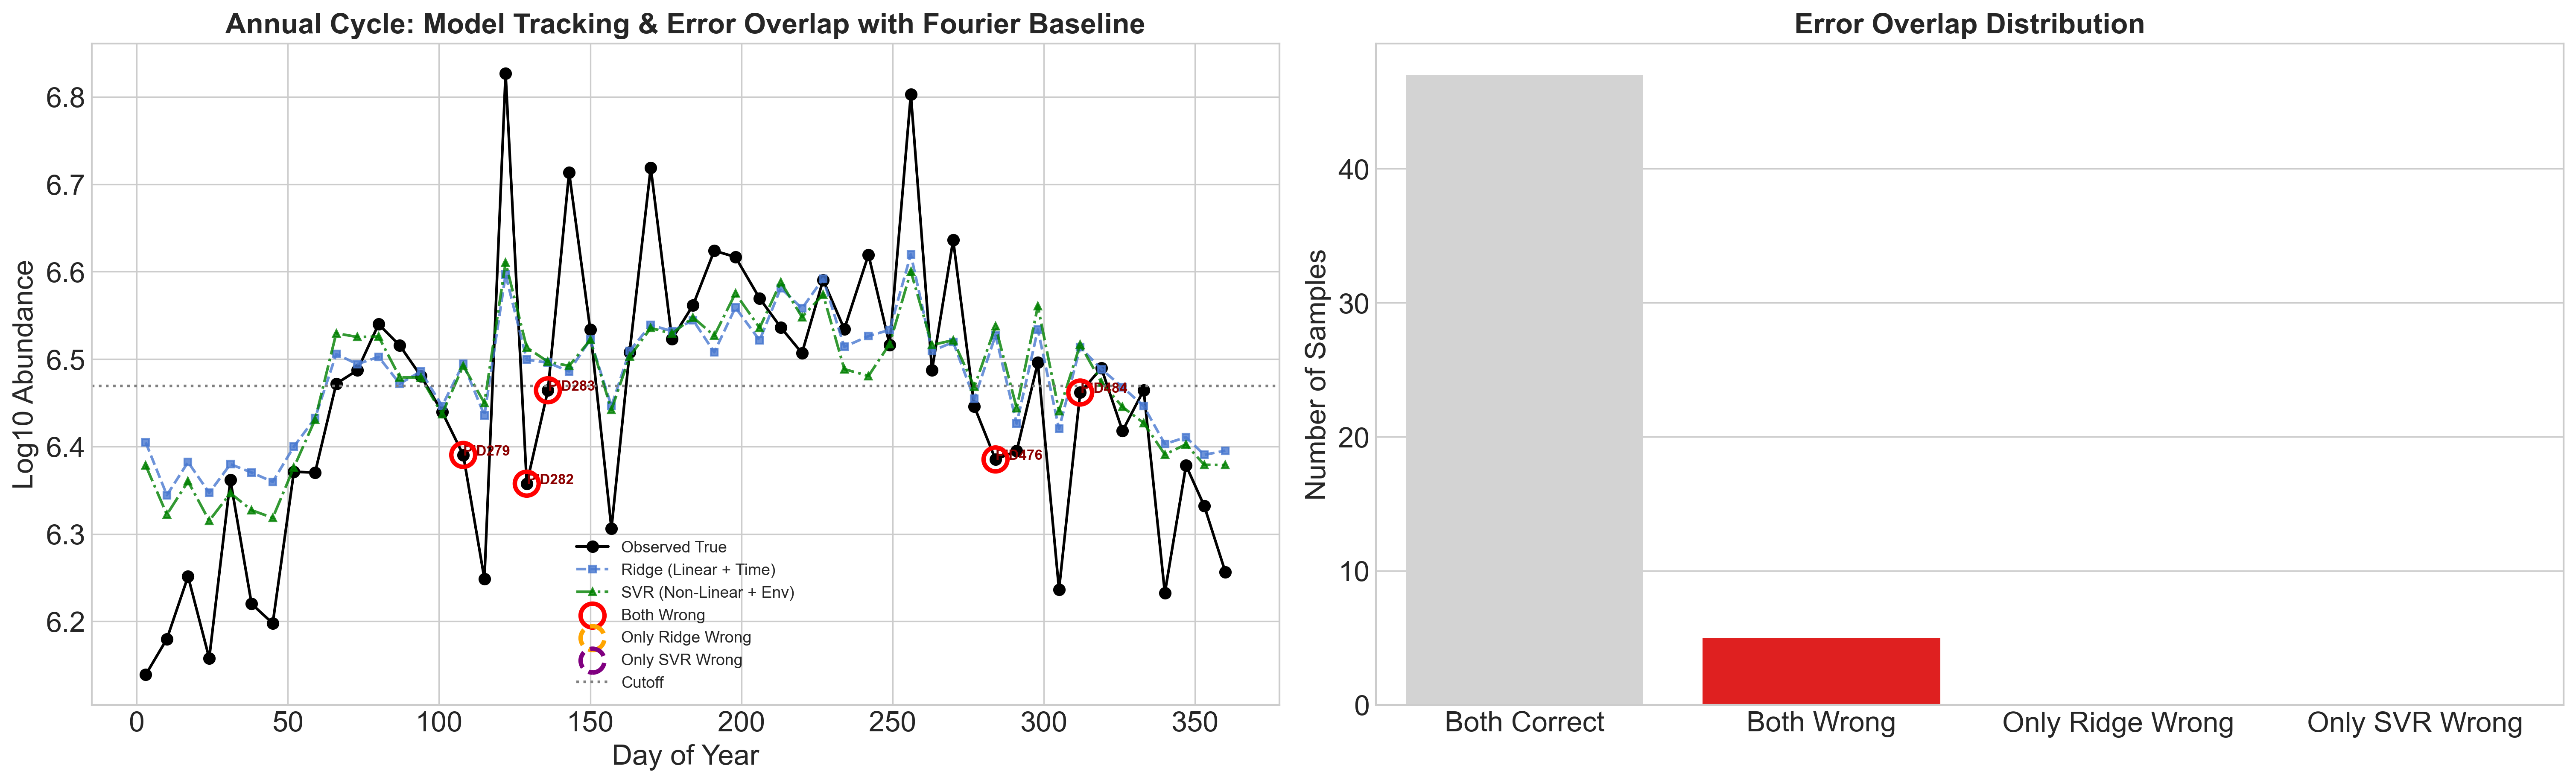

In [14]:
df_compare = main_testing[["SampleID", "DayOfYear", "Season", "LogAbundance"]].copy()
df_compare["TrueClass"] = y_test
df_compare["Ridge_LogPred"] = year_ridge_log_predictions
df_compare["Ridge_Class"] = year_ridge_predictions
df_compare["Ridge_Correct"] = df_compare["Ridge_Class"] == df_compare["TrueClass"]
df_compare["SVR_LogPred"] = svr_log_predictions
df_compare["SVR_Class"] = svr_predictions
df_compare["SVR_Correct"] = df_compare["SVR_Class"] == df_compare["TrueClass"]

def categorize_error(row):
    if not row["Ridge_Correct"] and not row["SVR_Correct"]: return "Both Wrong"
    elif not row["Ridge_Correct"]: return "Only Ridge Wrong"
    elif not row["SVR_Correct"]: return "Only SVR Wrong"
    else: return "Both Correct"

df_compare["ErrorType"] = df_compare.apply(categorize_error, axis=1)
svr_pipe = svr_search.best_estimator_
ridge_pipe = year_ridge_search.best_estimator_

X_train_svr = svr_pipe.named_steps["standardize"].transform(svr_pipe.named_steps["impute"].transform(main_training[svr_features]))
X_test_svr = svr_pipe.named_steps["standardize"].transform(svr_pipe.named_steps["impute"].transform(main_testing[svr_features]))
dist_svr = pairwise_distances(X_test_svr, X_train_svr).min(axis=1)

X_train_ridge = ridge_pipe.named_steps["standardize"].transform(ridge_pipe.named_steps["impute"].transform(main_training[ridge_features]))
X_test_ridge = ridge_pipe.named_steps["standardize"].transform(ridge_pipe.named_steps["impute"].transform(main_testing[ridge_features]))
dist_ridge = pairwise_distances(X_test_ridge, X_train_ridge).min(axis=1)

svr_df = df_compare.copy()
svr_df["Model"] = "SVR (Non-Linear Env)"
svr_df["Distance_from_cutoff"] = np.abs(svr_df["LogAbundance"] - main_cutoff)
svr_df["Nearest_training_distance"] = dist_svr
svr_df["Correct"] = svr_df["SVR_Correct"]

ridge_df = df_compare.copy()
ridge_df["Model"] = "Ridge (Linear + High-Freq Time)"
ridge_df["Distance_from_cutoff"] = np.abs(ridge_df["LogAbundance"] - main_cutoff)
ridge_df["Nearest_training_distance"] = dist_ridge
ridge_df["Correct"] = ridge_df["Ridge_Correct"]

combined_df = pd.concat([ridge_df, svr_df], ignore_index=True)

fig1, axes1 = plt.subplots(1, 2, figsize=(20, 6), constrained_layout=True)
ordered = df_compare.sort_values("DayOfYear")

axes1[0].plot(ordered["DayOfYear"], ordered["LogAbundance"], marker="o", color="black", linewidth=1.5, label="Observed True")
axes1[0].plot(ordered["DayOfYear"], ordered["Ridge_LogPred"], marker="s", markersize=4, linestyle="--", alpha=0.8, color="C0", label="Ridge (Linear + Time)")
axes1[0].plot(ordered["DayOfYear"], ordered["SVR_LogPred"], marker="^", markersize=4, linestyle="-.", alpha=0.8, color="green", label="SVR (Non-Linear + Env)")

both_w = ordered[ordered["ErrorType"] == "Both Wrong"]
ridge_w = ordered[ordered["ErrorType"] == "Only Ridge Wrong"]
svr_w = ordered[ordered["ErrorType"] == "Only SVR Wrong"]

axes1[0].scatter(both_w["DayOfYear"], both_w["LogAbundance"], s=180, facecolors="none", edgecolors="red", linewidth=2.5, label="Both Wrong", zorder=5)
axes1[0].scatter(ridge_w["DayOfYear"], ridge_w["LogAbundance"], s=180, facecolors="none", edgecolors="orange", linewidth=2.5, linestyle="--", label="Only Ridge Wrong", zorder=5)
axes1[0].scatter(svr_w["DayOfYear"], svr_w["LogAbundance"], s=180, facecolors="none", edgecolors="purple", linewidth=2.5, linestyle="--", label="Only SVR Wrong", zorder=5)

texts = []
for _, row in ordered[ordered["ErrorType"] != "Both Correct"].iterrows():
    texts.append(axes1[0].text(row["DayOfYear"], row["LogAbundance"], str(row["SampleID"]), fontsize=8, color="darkred", weight="bold"))

axes1[0].axhline(main_cutoff, color="grey", linestyle=":", label="Cutoff")
axes1[0].set(title="Annual Cycle: Model Tracking & Error Overlap with Fourier Baseline", xlabel="Day of Year", ylabel="Log10 Abundance")
axes1[0].legend(fontsize=9, loc="lower center")

sns.countplot(data=df_compare, x="ErrorType", 
              order=["Both Correct", "Both Wrong", "Only Ridge Wrong", "Only SVR Wrong"], 
              palette=["lightgrey", "red", "orange", "purple"], ax=axes1[1])
axes1[1].set(title="Error Overlap Distribution", ylabel="Number of Samples", xlabel="")
plt.show()

## 3. Disscussion: Where does the best strategy fail?

In [15]:

from sklearn.metrics import pairwise_distances

svr_pipeline = svr_search.best_estimator_
ridge_pipeline = year_ridge_search.best_estimator_

X_train_svr = svr_pipeline.named_steps["standardize"].transform(
    svr_pipeline.named_steps["impute"].transform(main_training[svr_features])
)
X_test_svr = svr_pipeline.named_steps["standardize"].transform(
    svr_pipeline.named_steps["impute"].transform(main_testing[svr_features])
)
dist_svr = pairwise_distances(X_test_svr, X_train_svr).min(axis=1)

X_train_ridge = ridge_pipeline.named_steps["standardize"].transform(
    ridge_pipeline.named_steps["impute"].transform(main_training[ridge_features])
)
X_test_ridge = ridge_pipeline.named_steps["standardize"].transform(
    ridge_pipeline.named_steps["impute"].transform(main_testing[ridge_features])
)
dist_ridge = pairwise_distances(X_test_ridge, X_train_ridge).min(axis=1)

base_df = main_testing[["SampleID", "DayOfYear", "Season", "LogAbundance"]].copy()
for feat in environmental_features:
    base_df[feat] = main_testing[feat]
base_df["TrueClass"] = y_test
base_df["Distance_from_cutoff"] = np.abs(base_df["LogAbundance"] - main_cutoff)


svr_df = base_df.copy()
svr_df["Model"] = "SVR (Non-Linear Env)"
svr_df["PredictedLogAbundance"] = svr_log_predictions
svr_df["PredictedClass"] = svr_predictions
svr_df["Correct"] = (svr_df["PredictedClass"] == svr_df["TrueClass"])
svr_df["Nearest_training_distance"] = dist_svr
ridge_df = base_df.copy()
ridge_df["Model"] = "Ridge (Linear + High-Freq Time)"
ridge_df["PredictedLogAbundance"] = year_ridge_log_predictions
ridge_df["PredictedClass"] = year_ridge_predictions
ridge_df["Correct"] = (ridge_df["PredictedClass"] == ridge_df["TrueClass"])
ridge_df["Nearest_training_distance"] = dist_ridge
combined_df = pd.concat([ridge_df, svr_df], ignore_index=True)
errors_only = combined_df[~combined_df["Correct"]].sort_values(
    by=["Model", "Distance_from_cutoff"], ascending=[True, False]
)

display_cols = [
    "Model", "SampleID", "DayOfYear", "Distance_from_cutoff", 
    "Nearest_training_distance", "LogAbundance", "PredictedLogAbundance"
] + environmental_features
display(errors_only[display_cols].round(3))

,Model,SampleID,DayOfYear,Distance_from_cutoff,Nearest_training_distance,LogAbundance,PredictedLogAbundance,Temp,MLLW,Salinity,Log1p_DIC,Log1p_Chlorophyll,Log1p_PO4,Log1p_SiO4,Log1p_DIN
18,Ridge (Linear + High-Freq Time),PID282,129,0.112,3.080,6.357,6.499,21.8,1.12,34.0,7.677,1.581,0.000,1.535,0.231
40,Ridge (Linear + High-Freq Time),PID476,284,0.084,2.790,6.385,6.527,21.5,0.30,30.0,7.613,2.537,0.095,2.501,0.186
15,Ridge (Linear + High-Freq Time),PID279,108,0.079,2.351,6.390,6.495,19.7,0.05,33.0,7.664,1.330,0.039,0.997,0.283
44,Ridge (Linear + High-Freq Time),PID484,312,0.007,2.799,6.462,6.514,12.7,0.86,32.0,7.609,1.820,0.058,2.393,0.136
19,Ridge (Linear + High-Freq Time),PID283,136,0.005,3.265,6.464,6.496,22.8,0.07,35.0,7.684,1.807,0.000,0.815,0.205
70,SVR (Non-Linear Env),PID282,129,0.112,3.080,6.357,6.513,21.8,1.12,34.0,7.677,1.581,0.000,1.535,0.231
92,SVR (Non-Linear Env),PID476,284,0.084,2.790,6.385,6.537,21.5,0.30,30.0,7.613,2.537,0.095,2.501,0.186
67,SVR (Non-Linear Env),PID279,108,0.079,2.351,6.390,6.492,19.7,0.05,33.0,7.664,1.330,0.039,0.997,0.283
96,SVR (Non-Linear Env),PID484,312,0.007,2.799,6.462,6.517,12.7,0.86,32.0,7.609,1.820,0.058,2.393,0.136
71,SVR (Non-Linear Env),PID283,136,0.005,3.265,6.464,6.497,22.8,0.07,35.0,7.684,1.807,0.000,0.815,0.205


**Implication of Misclassifications**

Both models predominantly fail on boundary cases. The `Distance_from_cutoff` for these errors is exceptionally small (mostly < 0.1). So it is more like a cutoff problem than model failure.

## 4. Final stress test: rotate the held-out year

For each experiment, the cutoff, imputation, scaling and alpha are re-estimated from the two training years.

**Implication of the stress test**

Rotating the held-out year reveals substantial interannual variation in model performance. On Year 1, SVR achieved 68.1% accuracy, compared with 59.6% for Ridge. On Year 3, Ridge achieved 75.0%, compared with 71.2% for SVR. Both results are lower than the 90.4% accuracy obtained by both models on Year 2.

The error-overlap plots show that many difficult samples were misclassified by both models: 14 of 47 samples in Year 1 and 13 of 52 samples in Year 3. These shared errors often occur where the observed abundance departs sharply from the smooth seasonal cycle, suggesting that unusual short-term ecological variability is not fully represented by the selected temporal and environmental predictors. The red dots outliner of the environmental features such as log(PO4) and log(DIN) also shows the yearly variability of the enironmental features.
Neither model is consistently superior across all years. SVR performs better for Year 1, whereas Ridge performs better for Year 3. Thus, the strong Year 2 result should not be interpreted as a universal accuracy level. Instead, the stress test shows that the models capture the broad seasonal structure but generalize unevenly when the environmental–abundance relationship changes between years.

## 5. Conclusions

This analysis investigated whether continuous seasonal timing and environmental measurements can improve the classification of weekly bacterial abundance as Low or High. Replacing four categorical seasons with continuous Fourier harmonics increased the held-out Year 2 accuracy from 75.0% to 80.8%, indicating that bacterial abundance follows gradual seasonal transitions that are not fully represented by fixed calendar boundaries.

After temporal and environmental predictors were combined, both the periodic Ridge model and the nonlinear SVR model achieved 90.4% accuracy on Year 2. Most of their errors occurred close to the Low/High cutoff, meaning that relatively small abundance differences could change the assigned class. The models therefore reproduced the main abundance pattern more successfully than the binary error count alone might suggest.

The rotating-year stress test produced lower accuracies for Years 1 and 3 and showed that the better-performing model changed between years. Ridge provided a smooth and interpretable representation of the annual cycle, while SVR offered additional flexibility for nonlinear environmental relationships. However, neither method was consistently best under every interannual condition. The main limitations are the dataset’s coarse weekly sampling and it small size. Short-term environmental changes between samples are not recorded, which limits the models’ ability to predict rapid changes in bacterial abundance.

### References

- Ward, C. S. *et al.* (2017). [Annual community patterns are driven by seasonal switching between closely related marine bacteria](https://www.nature.com/articles/ismej20174). *The ISME Journal*, 11, 1412–1422.
- Course dataset: [PIDweekly_env_data.txt](https://github.com/julianmak/OCES4303_ML_ocean/blob/main/PIDweekly_env_data.txt).
- PICO dataset* (2025): [PICO_biogeochemical_data] collected from Duke Marine Lab dock from 2011-2022. *BCO-DMO* https://www.bco-dmo.org/dataset/956182 